Write a program to generate following noises using equations derived
from PDFs of noise distributions. Compare your output with those
generated using inbuilt function imnoise. Plot the histograms of generated
noise to determine the shape of the distribution.
1. Uniform noise
2. Gaussian noise
3. Erlang noise
4. Exponential noise
5. Rayleigh noise

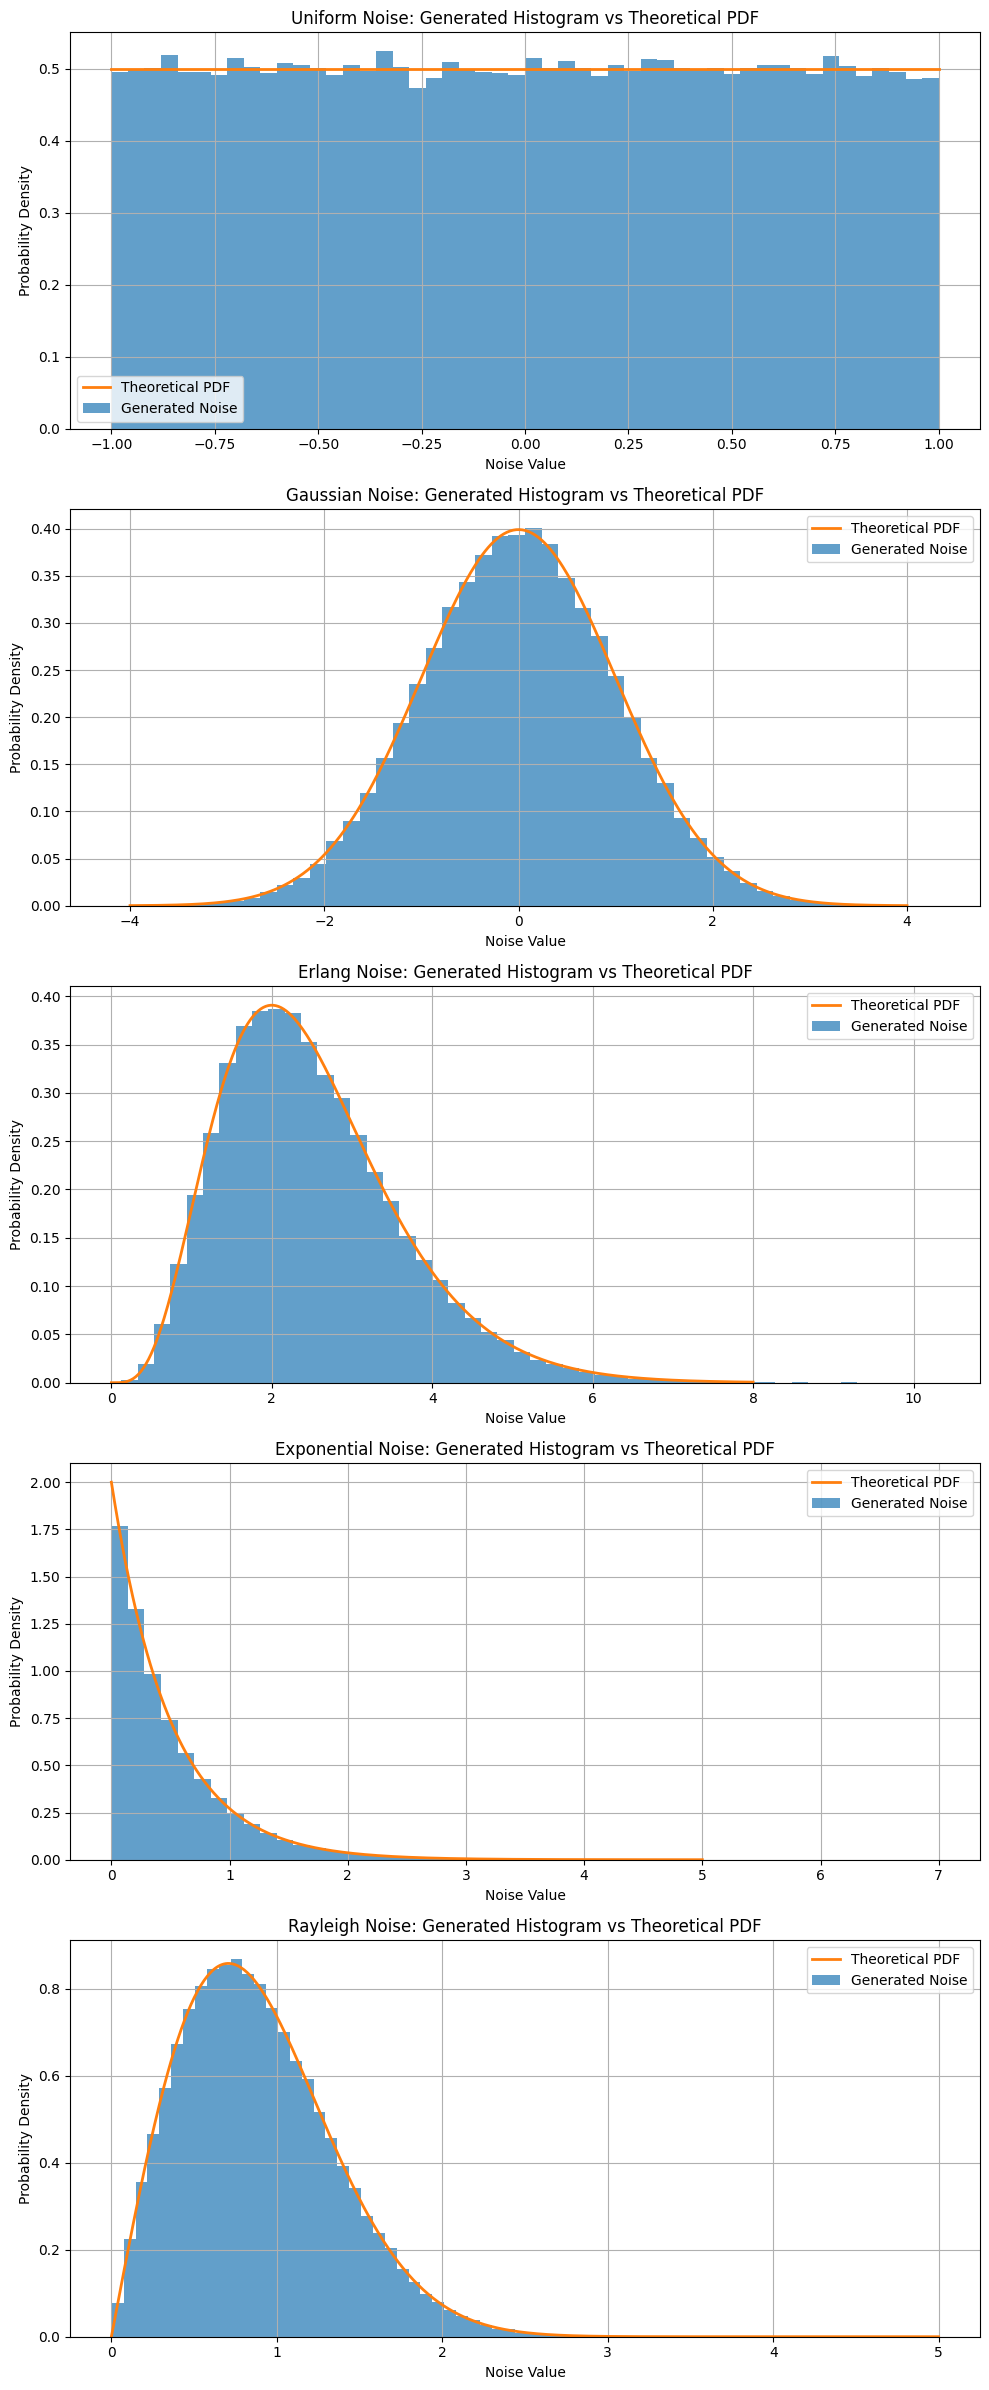

In [2]:
# ============================================================
# NOISE GENERATION USING PDF EQUATIONS
# Uniform, Gaussian, Erlang, Exponential and Rayleigh
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import math

# Number of samples
N = 100000

# For reproducible results
np.random.seed(42)


# ============================================================
# 1. UNIFORM NOISE
# ============================================================
# PDF from the given PDF:
#
#             1
# p(z) =  ---------       for a <= z <= b
#           b - a
#
#             0           otherwise
#
# Inverse transformation:
#
# z = a + (b-a)r
#
# where r is uniformly distributed in [0,1].
# ============================================================

a_uniform = -1
b_uniform = 1

r = np.random.rand(N)

uniform_noise = a_uniform + (b_uniform - a_uniform) * r


# Theoretical Uniform PDF
x_uniform = np.linspace(a_uniform, b_uniform, 500)

pdf_uniform = np.ones_like(x_uniform) / (
    b_uniform - a_uniform
)


# ============================================================
# 2. GAUSSIAN NOISE
# ============================================================
# PDF from the given PDF:
#
#              1
# p(z) = ---------------- exp[-(z-zbar)^2/(2*sigma^2)]
#          sqrt(2*pi)*sigma
#
# PDF specifies ideal case:
# zbar = 0
# sigma = 1
#
# We use Box-Muller transformation:
#
# z = zbar + sigma*sqrt(-2*ln(r1))*cos(2*pi*r2)
# ============================================================

mu = 0
sigma = 1

r1 = np.random.rand(N)
r2 = np.random.rand(N)

gaussian_noise = (
    mu
    + sigma * np.sqrt(-2 * np.log(r1))
    * np.cos(2 * np.pi * r2)
)


# Theoretical Gaussian PDF
x_gaussian = np.linspace(-4, 4, 500)

pdf_gaussian = (
    1 / (np.sqrt(2 * np.pi) * sigma)
    * np.exp(
        -((x_gaussian - mu) ** 2)
        / (2 * sigma ** 2)
    )
)


# ============================================================
# 3. ERLANG (GAMMA) NOISE
# ============================================================
# PDF from the given PDF:
#
#              a^b * z^(b-1) * exp(-a*z)
# p(z) = --------------------------------
#                    (b-1)!
#
# for z >= 0
#
# Erlang noise can be generated as the SUM of b
# exponential random variables:
#
# z = -(1/a) * [ln(r1) + ln(r2) + ... + ln(rb)]
# ============================================================

a_erlang = 2
b_erlang = 5

erlang_noise = np.zeros(N)

for i in range(b_erlang):
    r = np.random.rand(N)

    erlang_noise += (
        -(1 / a_erlang) * np.log(r)
    )


# Theoretical Erlang PDF
x_erlang = np.linspace(0, 8, 500)

pdf_erlang = (
    (a_erlang ** b_erlang)
    * (x_erlang ** (b_erlang - 1))
    * np.exp(-a_erlang * x_erlang)
    / math.factorial(b_erlang - 1)
)


# ============================================================
# 4. EXPONENTIAL NOISE
# ============================================================
# PDF from the given PDF:
#
# p(z) = a*exp(-a*z)       for z >= 0
#        0                  for z < 0
#
# Inverse transformation:
#
# z = -(1/a)*ln(r)
# ============================================================

a_exp = 2

r = np.random.rand(N)

exponential_noise = (
    -(1 / a_exp) * np.log(r)
)


# Theoretical Exponential PDF
x_exponential = np.linspace(0, 5, 500)

pdf_exponential = (
    a_exp * np.exp(-a_exp * x_exponential)
)


# ============================================================
# 5. RAYLEIGH NOISE
# ============================================================
# PDF from the given PDF:
#
#               2(z-a)
# p(z) = ---------------- exp[-(z-a)^2/b^2]
#                 b^2
#
# for z >= a
#
# Inverse transformation:
#
# z = a + b*sqrt(-ln(r))
# ============================================================

a_rayleigh = 0
b_rayleigh = 1

r = np.random.rand(N)

rayleigh_noise = (
    a_rayleigh
    + b_rayleigh * np.sqrt(-np.log(r))
)


# Theoretical Rayleigh PDF
x_rayleigh = np.linspace(
    a_rayleigh,
    5,
    500
)

pdf_rayleigh = (
    (2 * (x_rayleigh - a_rayleigh)
     / (b_rayleigh ** 2))
    * np.exp(
        -((x_rayleigh - a_rayleigh) ** 2)
        / (b_rayleigh ** 2)
    )
)


# ============================================================
# PLOT HISTOGRAMS + THEORETICAL PDFs
# ============================================================

fig, axes = plt.subplots(5, 1, figsize=(10, 24))

# ---------------- UNIFORM ----------------
axes[0].hist(
    uniform_noise,
    bins=50,
    density=True,
    alpha=0.7
)

axes[0].plot(
    x_uniform,
    pdf_uniform,
    linewidth=2
)

axes[0].set_title(
    "Uniform Noise: Generated Histogram vs Theoretical PDF"
)

axes[0].set_xlabel("Noise Value")
axes[0].set_ylabel("Probability Density")
axes[0].legend(
    ["Theoretical PDF", "Generated Noise"]
)
axes[0].grid(True)


# ---------------- GAUSSIAN ----------------
axes[1].hist(
    gaussian_noise,
    bins=50,
    density=True,
    alpha=0.7
)

axes[1].plot(
    x_gaussian,
    pdf_gaussian,
    linewidth=2
)

axes[1].set_title(
    "Gaussian Noise: Generated Histogram vs Theoretical PDF"
)

axes[1].set_xlabel("Noise Value")
axes[1].set_ylabel("Probability Density")
axes[1].legend(
    ["Theoretical PDF", "Generated Noise"]
)
axes[1].grid(True)


# ---------------- ERLANG ----------------
axes[2].hist(
    erlang_noise,
    bins=50,
    density=True,
    alpha=0.7
)

axes[2].plot(
    x_erlang,
    pdf_erlang,
    linewidth=2
)

axes[2].set_title(
    "Erlang Noise: Generated Histogram vs Theoretical PDF"
)

axes[2].set_xlabel("Noise Value")
axes[2].set_ylabel("Probability Density")
axes[2].legend(
    ["Theoretical PDF", "Generated Noise"]
)
axes[2].grid(True)


# ---------------- EXPONENTIAL ----------------
axes[3].hist(
    exponential_noise,
    bins=50,
    density=True,
    alpha=0.7
)

axes[3].plot(
    x_exponential,
    pdf_exponential,
    linewidth=2
)

axes[3].set_title(
    "Exponential Noise: Generated Histogram vs Theoretical PDF"
)

axes[3].set_xlabel("Noise Value")
axes[3].set_ylabel("Probability Density")
axes[3].legend(
    ["Theoretical PDF", "Generated Noise"]
)
axes[3].grid(True)


# ---------------- RAYLEIGH ----------------
axes[4].hist(
    rayleigh_noise,
    bins=50,
    density=True,
    alpha=0.7
)

axes[4].plot(
    x_rayleigh,
    pdf_rayleigh,
    linewidth=2
)

axes[4].set_title(
    "Rayleigh Noise: Generated Histogram vs Theoretical PDF"
)

axes[4].set_xlabel("Noise Value")
axes[4].set_ylabel("Probability Density")
axes[4].legend(
    ["Theoretical PDF", "Generated Noise"]
)
axes[4].grid(True)


plt.tight_layout()
plt.show()

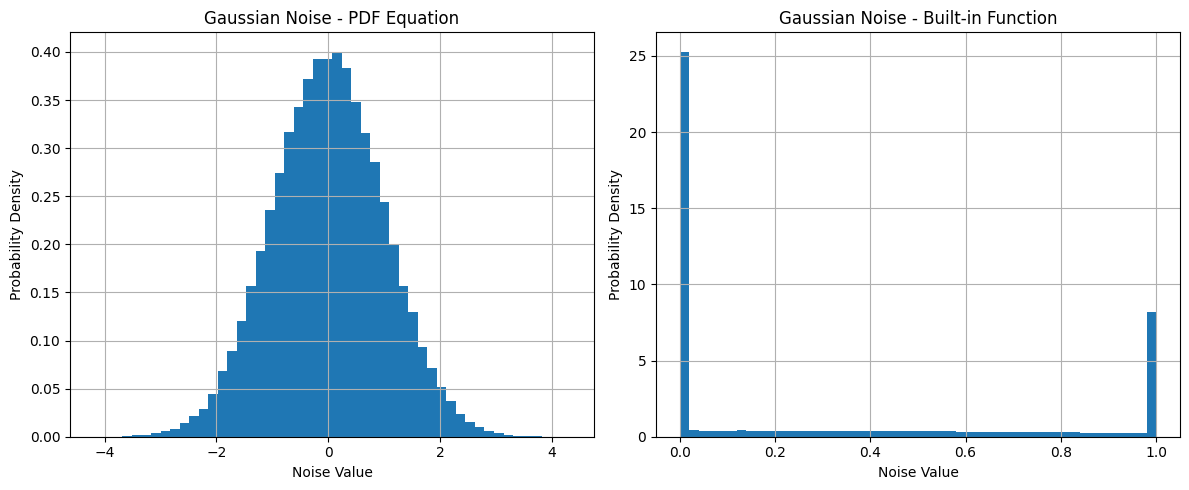

In [3]:
# ============================================================
# BUILT-IN GAUSSIAN NOISE COMPARISON
# ============================================================

!pip -q install scikit-image

from skimage.util import random_noise

# Create a zero-valued image
image = np.zeros((500, 500))

# Built-in Gaussian noise
builtin_gaussian = random_noise(
    image,
    mode='gaussian',
    mean=mu,
    var=sigma**2
)

builtin_gaussian = builtin_gaussian.flatten()


# Compare manually generated Gaussian noise
# with built-in Gaussian noise

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.hist(
    gaussian_noise,
    bins=50,
    density=True
)

plt.title("Gaussian Noise - PDF Equation")
plt.xlabel("Noise Value")
plt.ylabel("Probability Density")
plt.grid(True)


plt.subplot(1, 2, 2)

plt.hist(
    builtin_gaussian,
    bins=50,
    density=True
)

plt.title("Gaussian Noise - Built-in Function")
plt.xlabel("Noise Value")
plt.ylabel("Probability Density")
plt.grid(True)

plt.tight_layout()
plt.show()

In [4]:
print("========== NOISE STATISTICS ==========")

print("\nUniform Noise")
print("Mean     :", np.mean(uniform_noise))
print("Variance :", np.var(uniform_noise))

print("\nGaussian Noise")
print("Mean     :", np.mean(gaussian_noise))
print("Variance :", np.var(gaussian_noise))

print("\nErlang Noise")
print("Mean     :", np.mean(erlang_noise))
print("Variance :", np.var(erlang_noise))

print("\nExponential Noise")
print("Mean     :", np.mean(exponential_noise))
print("Variance :", np.var(exponential_noise))

print("\nRayleigh Noise")
print("Mean     :", np.mean(rayleigh_noise))
print("Variance :", np.var(rayleigh_noise))

========== NOISE STATISTICS ==========

Uniform Noise
Mean     : -0.0010234998529259761
Variance : 0.3325598346246482

Gaussian Noise
Mean     : 0.0007284450000859169
Variance : 0.9930578658366155

Erlang Noise
Mean     : 2.4972783777113845
Variance : 1.2364166656217421

Exponential Noise
Mean     : 0.49874961796760736
Variance : 0.2538698298617777

Rayleigh Noise
Mean     : 0.8862009222281078
Variance : 0.21375390893464064
